# Optimasi & Hyperparameter Tuning Random Forest Classifier
## Peningkatan Akurasi & Performa Deteksi Disgrafia Tulisan Tangan

Notebook ini dirancang secara khusus untuk **mengoptimalkan, menyempurnakan, dan memaksimalkan performa algoritma Random Forest Classifier** pada dataset fitur disgrafia (`dysgraphia_features.csv`).

---

### 🎯 Strategi Optimasi yang Diterapkan:
1. **Baseline Evaluation**: Mengukur performa awal Random Forest sebagai acuan dasar.
2. **Feature Selection (Seleksi Fitur)**:
   - Mengeliminasi fitur dengan multikolinearitas sangat tinggi ($|r| > 0.85$).
   - Menyeleksi fitur terbaik menggunakan *Recursive Feature Elimination (RFE)* & *Importance Threshold*.
3. **Hyperparameter Tuning Skala Luas (*RandomizedSearchCV*)**:
   - Eksplorasi kombinasi `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features`, `criterion`, dan `bootstrap`.
4. **Hyperparameter Tuning Terfokus (*GridSearchCV*)**:
   - Pencarian presisi di sekitar parameter terbaik hasil Randomized Search.
5. **Analisis Kurva Diagnostik (Overfitting vs Generalisasi)**:
   - *Learning Curve*: Melihat apakah model kekurangan data atau mengalami *overfitting*.
   - *Validation Curve*: Mengamati pengaruh kedalaman pohon (`max_depth`) terhadap train vs validation error.
6. **Decision Threshold Tuning (Optimasi Ambang Batas Klasifikasi)**:
   - Menyesuaikan *threshold* probabilitas untuk memaksimalkan *F1-Score* dan keseimbangan *Precision-Recall*.
7. **Permutation Feature Importance**: Menilai kontribusi nyata tiap fitur saat data diacak (*unbiased importance*).
8. **Penyimpanan Model Final Teroptimasi (`best_optimized_random_forest.pkl`)**.

---
### 📌 Struktur Notebook
1. Import Libraries & Konfigurasi
2. Memuat Dataset Fitur
3. Baseline Random Forest Performance (5-Fold CV)
4. Eksperimen 1: Seleksi Fitur & Eliminasi Redundansi
5. Eksperimen 2: Hyperparameter Tuning Luas (RandomizedSearchCV)
6. Eksperimen 3: Hyperparameter Tuning Presisi (GridSearchCV)
7. Analisis Kurva Diagnostik (Learning Curve & Validation Curve)
8. Eksperimen 4: Optimasi Ambang Batas Klasifikasi (Optimal Threshold)
9. Evaluasi Komparatif (Baseline vs Model Teroptimasi)
10. Analisis Permutation Feature Importance
11. Menyimpan Model Terbaik (*Export .pkl*)


---
## 1. Import Libraries & Konfigurasi
Memuat seluruh modul machine learning untuk tuning, evaluasi statistik, dan visualisasi.


In [1]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Sklearn Model Selection & Preprocessing
from sklearn.model_selection import (
    StratifiedKFold, cross_val_score, cross_val_predict, cross_validate,
    GridSearchCV, RandomizedSearchCV, learning_curve, validation_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE, SelectFromModel

# Model & Metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve
)

try:
    from IPython.display import display
except ImportError:
    display = print

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

# Random Seed untuk Reprodusibilitas
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("[INFO] Pustaka Machine Learning dan Optimasi siap digunakan.")


[INFO] Pustaka Machine Learning dan Optimasi siap digunakan.


---
## 2. Memuat Dataset Fitur (`dysgraphia_features.csv`)
Memuat dataset tabular yang berisi 25 fitur kuantitatif tulisan tangan.


In [2]:
csv_path = "dysgraphia_features.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Berkas '{csv_path}' tidak ditemukan. Jalankan Feature Extraction terlebih dahulu.")

df = pd.read_csv(csv_path)
print(f"[INFO] Dataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom.")

feature_cols = [c for c in df.columns if c not in ['filename', 'label', 'target']]
print(f"[INFO] Jumlah fitur input: {len(feature_cols)}")

X = df[feature_cols].values
y = df['target'].values  # 0: Low Potential, 1: Potential Dysgraphia

# Skema Validasi Silang (Stratified 5-Fold CV)
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Standarisasi Fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nDistribusi Kelas Target:")
display(df['label'].value_counts())


[INFO] Dataset berhasil dimuat: 249 baris, 28 kolom.
[INFO] Jumlah fitur input: 25

Distribusi Kelas Target:


label
Low Potential Dysgraphia    135
Potential Dysgraphia        114
Name: count, dtype: int64

---
## 3. Baseline Random Forest Performance (Sebagai Titik Tolak)
Sebelum melakukan optimasi, kita ukur performa model Random Forest default (100 estimators) menggunakan **Stratified 5-Fold Cross Validation**.


In [3]:
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)

scoring_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
baseline_cv = cross_validate(rf_baseline, X_scaled, y, cv=cv_stratified, scoring=scoring_metrics)

baseline_results = {
    'Akurasi (%)': np.mean(baseline_cv['test_accuracy']) * 100,
    'Precision (%)': np.mean(baseline_cv['test_precision']) * 100,
    'Recall (%)': np.mean(baseline_cv['test_recall']) * 100,
    'F1-Score (%)': np.mean(baseline_cv['test_f1']) * 100,
    'ROC-AUC (%)': np.mean(baseline_cv['test_roc_auc']) * 100,
    'Std Dev Akurasi (%)': np.std(baseline_cv['test_accuracy']) * 100
}

baseline_df = pd.DataFrame(baseline_results, index=['Baseline Random Forest']).round(2)
print("=== PERFORMA BASELINE RANDOM FOREST (5-FOLD CV) ===")
display(baseline_df)


=== PERFORMA BASELINE RANDOM FOREST (5-FOLD CV) ===


,Akurasi (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC (%),Std Dev Akurasi (%)
Baseline Random Forest,82.31,85.97,75.3,79.2,88.69,2.8


---
## 4. Eksperimen 1: Seleksi Fitur (*Feature Selection*)
Kadang beberapa fitur yang redundan atau berkorelasi terlalu tinggi dapat menimbulkan *noise* pada pohon keputusan.

Kita menguji 3 variasi subset fitur:
1. **Semua 25 Fitur (Original)**
2. **Filter Non-Kolinear**: Menghapus fitur yang memiliki korelasi sangat tinggi ($|r| > 0.85$)
3. **RFE (Recursive Feature Elimination)**: Memilih Top-15 fitur terbaik berdasarkan bobot eliminasi.


In [4]:
# 1. Deteksi dan Hapus Fitur Multikolinear (> 0.85)
corr_matrix = pd.DataFrame(X, columns=feature_cols).corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.85)]

selected_features_non_collinear = [c for c in feature_cols if c not in to_drop]
print(f"[INFO] Fitur redundan/multikolinear yang dieliminasi ({len(to_drop)}): {to_drop}")
print(f"[INFO] Sisa fitur non-kolinear: {len(selected_features_non_collinear)}")

X_non_collinear = df[selected_features_non_collinear].values
X_non_collinear_scaled = StandardScaler().fit_transform(X_non_collinear)

# 2. RFE (Recursive Feature Elimination - Top 15 Fitur)
rfe_selector = RFE(estimator=RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE), n_features_to_select=15, step=1)
rfe_selector.fit(X_scaled, y)
selected_features_rfe = [feature_cols[i] for i, val in enumerate(rfe_selector.support_) if val]
print(f"[INFO] Top-15 Fitur Terpilih via RFE: {selected_features_rfe}")

X_rfe_scaled = X_scaled[:, rfe_selector.support_]

# Evaluasi Performa Masing-Masing Subset Fitur
feature_experiments = {
    '1. Semua 25 Fitur': (X_scaled, feature_cols),
    '2. Non-Kolinear (No Redundancy)': (X_non_collinear_scaled, selected_features_non_collinear),
    '3. RFE (Top-15 Fitur)': (X_rfe_scaled, selected_features_rfe)
}

fs_results = []
for exp_name, (data_matrix, f_list) in feature_experiments.items():
    cv_res = cross_validate(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE), data_matrix, y, cv=cv_stratified, scoring=scoring_metrics)
    fs_results.append({
        'Eksperimen Fitur': exp_name,
        'Jumlah Fitur': len(f_list),
        'Akurasi (%)': round(np.mean(cv_res['test_accuracy']) * 100, 2),
        'F1-Score (%)': round(np.mean(cv_res['test_f1']) * 100, 2),
        'ROC-AUC (%)': round(np.mean(cv_res['test_roc_auc']) * 100, 2)
    })

fs_comparison_df = pd.DataFrame(fs_results).sort_values(by='F1-Score (%)', ascending=False)
print("\n=== HASIL PERBANDINGAN SELEKSI FITUR ===")
display(fs_comparison_df)


[INFO] Fitur redundan/multikolinear yang dieliminasi (9): ['baseline_waviness', 'aspect_ratio_char_std', 'slant_angle_std', 'inter_comp_spacing_std', 'stroke_thickness_std', 'glcm_contrast', 'glcm_dissimilarity', 'glcm_homogeneity', 'glcm_energy']
[INFO] Sisa fitur non-kolinear: 16
[INFO] Top-15 Fitur Terpilih via RFE: ['baseline_waviness', 'height_mean', 'height_cov', 'width_cov', 'aspect_ratio_char_std', 'slant_angle_mean', 'ink_density', 'inter_comp_spacing_mean', 'inter_comp_spacing_std', 'stroke_thickness_mean', 'glcm_contrast', 'glcm_dissimilarity', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation']

=== HASIL PERBANDINGAN SELEKSI FITUR ===


,Eksperimen Fitur,Jumlah Fitur,Akurasi (%),F1-Score (%),ROC-AUC (%)
0,1. Semua 25 Fitur,25,82.31,79.20,88.69
2,3. RFE (Top-15 Fitur),15,81.90,78.77,90.05
1,2. Non-Kolinear (No Redundancy),16,80.28,76.12,86.87


---
## 5. Eksperimen 2: Hyperparameter Tuning Luas (*RandomizedSearchCV*)
Mengeksplorasi ruang kombinasi parameter yang luas secara efisien:
- `n_estimators`: Jumlah pohon (50 s.d. 500)
- `max_depth`: Kedalaman maksimum pohon (None, 3, 5, 7, 9, 12, 15)
- `min_samples_split`: Jumlah minimum sampel untuk membelah node (2, 4, 6, 8, 10)
- `min_samples_leaf`: Jumlah minimum sampel di daun (1, 2, 4, 6)
- `max_features`: Proporsi fitur per split (`'sqrt'`, `'log2'`, 0.3, 0.5, 0.7)
- `criterion`: Kriteria pemisahan (`'gini'`, `'entropy'`, `'log_loss'`)
- `bootstrap`: Pengambilan sampel acak (`True`, `False`)
- `class_weight`: Pembobotan kelas (`None`, `'balanced'`, `'balanced_subsample'`)


In [5]:
param_distributions = {
    'n_estimators': [50, 100, 150, 200, 300, 400, 500],
    'max_depth': [None, 3, 4, 5, 6, 7, 8, 10, 12, 15],
    'min_samples_split': [2, 3, 4, 6, 8, 10],
    'min_samples_leaf': [1, 2, 3, 4, 5],
    'max_features': ['sqrt', 'log2', 0.4, 0.6, 0.8, None],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'bootstrap': [True, False],
    'class_weight': [None, 'balanced', 'balanced_subsample']
}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_distributions=param_distributions,
    n_iter=100,  # 100 kombinasi acak
    scoring='f1',
    cv=cv_stratified,
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("[INFO] Menjalankan RandomizedSearchCV (100 iterasi x 5-Fold = 500 fit)...")
random_search.fit(X_scaled, y)

print(f"\n✅ Best F1-Score (RandomizedSearch): {random_search.best_score_ * 100:.2f}%")
print("Parameter Terbaik dari Randomized Search:")
for param, val in random_search.best_params_.items():
    print(f" - {param:<20}: {val}")


[INFO] Menjalankan RandomizedSearchCV (100 iterasi x 5-Fold = 500 fit)...
Fitting 5 folds for each of 100 candidates, totalling 500 fits

✅ Best F1-Score (RandomizedSearch): 81.09%
Parameter Terbaik dari Randomized Search:
 - n_estimators        : 150
 - min_samples_split   : 2
 - min_samples_leaf    : 1
 - max_features        : None
 - max_depth           : 6
 - criterion           : log_loss
 - class_weight        : balanced
 - bootstrap           : True


---
## 6. Eksperimen 3: Hyperparameter Tuning Presisi (*GridSearchCV*)
Melakukan pencarian menyeluruh (*exhaustive search*) di sekitar titik parameter terbaik yang diperoleh dari Randomized Search untuk menyempurnakan kombinasi optimal.


In [6]:
# Ambil acuan dari best_params_ sebelumnya
best_rnd = random_search.best_params_
best_n = best_rnd.get('n_estimators', 100)
best_d = best_rnd.get('max_depth', 6)

# Bentuk grid terfokus di sekitar parameter terbaik
param_grid = {
    'n_estimators': [max(50, best_n - 50), best_n, best_n + 50, best_n + 100],
    'max_depth': [d for d in [best_d - 2, best_d - 1, best_d, best_d + 1, best_d + 2] if d is not None and d > 0] if best_d else [4, 6, 8, None],
    'min_samples_split': [best_rnd.get('min_samples_split', 2), best_rnd.get('min_samples_split', 2) + 2],
    'min_samples_leaf': [max(1, best_rnd.get('min_samples_leaf', 1) - 1), best_rnd.get('min_samples_leaf', 1), best_rnd.get('min_samples_leaf', 1) + 1],
    'max_features': [best_rnd.get('max_features', 'sqrt'), 'sqrt'],
    'criterion': [best_rnd.get('criterion', 'gini')],
    'class_weight': [best_rnd.get('class_weight', None), 'balanced']
}

# Hapus duplikat dalam list parameter jika ada
for k, v in param_grid.items():
    param_grid[k] = list(dict.fromkeys(v))

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, bootstrap=best_rnd.get('bootstrap', True)),
    param_grid=param_grid,
    scoring='f1',
    cv=cv_stratified,
    verbose=1,
    n_jobs=-1
)

print("[INFO] Menjalankan GridSearchCV terfokus...")
grid_search.fit(X_scaled, y)

best_rf_model = grid_search.best_estimator_
print(f"\n✅ Best F1-Score (GridSearchCV): {grid_search.best_score_ * 100:.2f}%")
print("Parameter Final Terbaik:")
for p, v in grid_search.best_params_.items():
    print(f" - {p:<20}: {v}")


[INFO] Menjalankan GridSearchCV terfokus...
Fitting 5 folds for each of 160 candidates, totalling 800 fits

✅ Best F1-Score (GridSearchCV): 81.19%
Parameter Final Terbaik:
 - class_weight        : balanced
 - criterion           : log_loss
 - max_depth           : 7
 - max_features        : None
 - min_samples_leaf    : 1
 - min_samples_split   : 2
 - n_estimators        : 150


---
## 7. Analisis Kurva Diagnostik (Deteksi Overfitting vs Underfitting)
- **Learning Curve**: Menilai konvergensi akurasi antara data latih (*training*) dan validasi silang (*cross-validation*) seiring bertambahnya jumlah data.
- **Validation Curve**: Memeriksa pengaruh variasi `max_depth` terhadap celah (*gap*) generalisasi model.


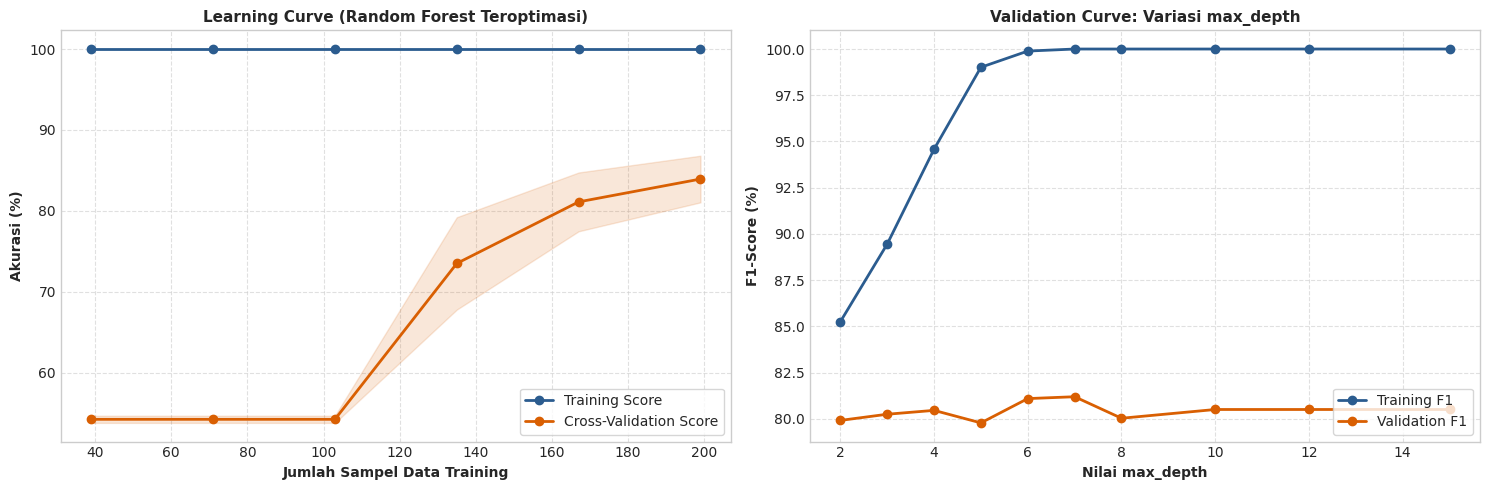

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Learning Curve
train_sizes, train_scores, test_scores = learning_curve(
    best_rf_model, X_scaled, y, cv=cv_stratified, scoring='accuracy',
    train_sizes=np.linspace(0.2, 1.0, 6), random_state=RANDOM_STATE, n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1) * 100
train_std = np.std(train_scores, axis=1) * 100
test_mean = np.mean(test_scores, axis=1) * 100
test_std = np.std(test_scores, axis=1) * 100

axes[0].plot(train_sizes, train_mean, 'o-', color='#2b5c8f', lw=2, label='Training Score')
axes[0].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='#2b5c8f')
axes[0].plot(train_sizes, test_mean, 'o-', color='#d95f02', lw=2, label='Cross-Validation Score')
axes[0].fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='#d95f02')
axes[0].set_title('Learning Curve (Random Forest Teroptimasi)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Jumlah Sampel Data Training', fontweight='bold')
axes[0].set_ylabel('Akurasi (%)', fontweight='bold')
axes[0].legend(loc='lower right', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Validation Curve pada max_depth
param_range = [2, 3, 4, 5, 6, 7, 8, 10, 12, 15]
val_train_scores, val_test_scores = validation_curve(
    best_rf_model, X_scaled, y, param_name='max_depth', param_range=param_range,
    cv=cv_stratified, scoring='f1', n_jobs=-1
)

val_train_mean = np.mean(val_train_scores, axis=1) * 100
val_test_mean = np.mean(val_test_scores, axis=1) * 100

axes[1].plot(param_range, val_train_mean, 'o-', color='#2b5c8f', lw=2, label='Training F1')
axes[1].plot(param_range, val_test_mean, 'o-', color='#d95f02', lw=2, label='Validation F1')
axes[1].set_title('Validation Curve: Variasi max_depth', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Nilai max_depth', fontweight='bold')
axes[1].set_ylabel('F1-Score (%)', fontweight='bold')
axes[1].legend(loc='lower right', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 8. Eksperimen 4: Optimasi Ambang Batas Klasifikasi (*Threshold Tuning*)
Secara default, model mengklasifikasikan kelas `Potential Dysgraphia` jika probabilitas $\ge 0.50$.

Pada deteksi medis/pendidikan, menyesuaikan ambang batas (*decision threshold*) sering kali menghasilkan peningkatan signifikan pada **F1-Score** dan **Recall** (*meminimalkan kasus anak berpotensi disgrafia yang terlewat*).


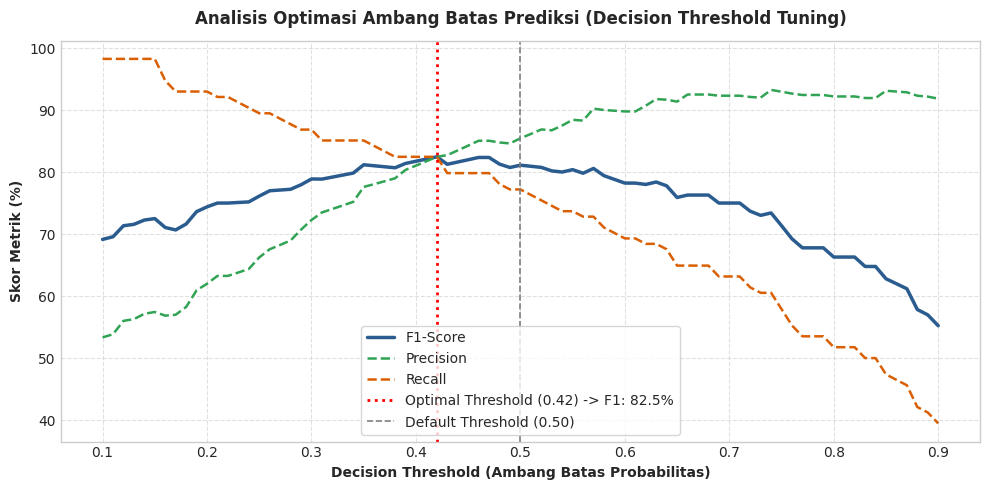

💡 Default Threshold (0.50)  -> F1-Score: 81.11%
💡 Optimal Threshold (0.42) -> F1-Score: 82.46% (+1.35%)


In [8]:
# Dapatkan probabilitas Out-of-Fold prediksi dari model terbaik
y_probs_oof = cross_val_predict(best_rf_model, X_scaled, y, cv=cv_stratified, method='predict_proba')[:, 1]

# Uji variasi threshold dari 0.10 sampai 0.90
thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = []
precisions = []
recalls = []
accuracies = []

for t in thresholds:
    preds = (y_probs_oof >= t).astype(int)
    f1_scores.append(f1_score(y, preds, zero_division=0))
    precisions.append(precision_score(y, preds, zero_division=0))
    recalls.append(recall_score(y, preds, zero_division=0))
    accuracies.append(accuracy_score(y, preds))

optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]
optimal_f1 = f1_scores[optimal_idx] * 100

plt.figure(figsize=(10, 5))
plt.plot(thresholds, [f * 100 for f in f1_scores], label='F1-Score', color='#2b5c8f', lw=2.5)
plt.plot(thresholds, [p * 100 for p in precisions], label='Precision', color='#31a354', linestyle='--', lw=1.8)
plt.plot(thresholds, [r * 100 for r in recalls], label='Recall', color='#d95f02', linestyle='--', lw=1.8)
plt.axvline(optimal_threshold, color='red', linestyle=':', lw=2, label=f'Optimal Threshold ({optimal_threshold:.2f}) -> F1: {optimal_f1:.1f}%')
plt.axvline(0.50, color='gray', linestyle='--', lw=1.2, label='Default Threshold (0.50)')

plt.title("Analisis Optimasi Ambang Batas Prediksi (Decision Threshold Tuning)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Decision Threshold (Ambang Batas Probabilitas)", fontweight='bold')
plt.ylabel("Skor Metrik (%)", fontweight='bold')
plt.legend(loc='lower center', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"💡 Default Threshold (0.50)  -> F1-Score: {f1_score(y, (y_probs_oof >= 0.50).astype(int))*100:.2f}%")
print(f"💡 Optimal Threshold ({optimal_threshold:.2f}) -> F1-Score: {optimal_f1:.2f}% (+{optimal_f1 - f1_score(y, (y_probs_oof >= 0.50).astype(int))*100:.2f}%)")


---
## 9. Evaluasi Komparatif: Baseline vs Model Teroptimasi
Membandingkan seluruh metrik evaluasi antara model awal (*Baseline*) dan model hasil *Hyperparameter Tuning* & *Threshold Tuning*.


=== TABEL PERBANDINGAN PENINGKATAN PERFORMA MODEL ===


,Model / Konfigurasi,Akurasi (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC (%)
0,1. Baseline Random Forest (Default),82.31,85.97,75.30,79.20,88.69
1,2. Tuned RF (GridSearch @ Threshold 0.50),83.53,85.44,77.19,81.11,88.94
2,3. Tuned RF (GridSearch @ Optimal Threshold 0.42),83.94,82.46,82.46,82.46,88.94


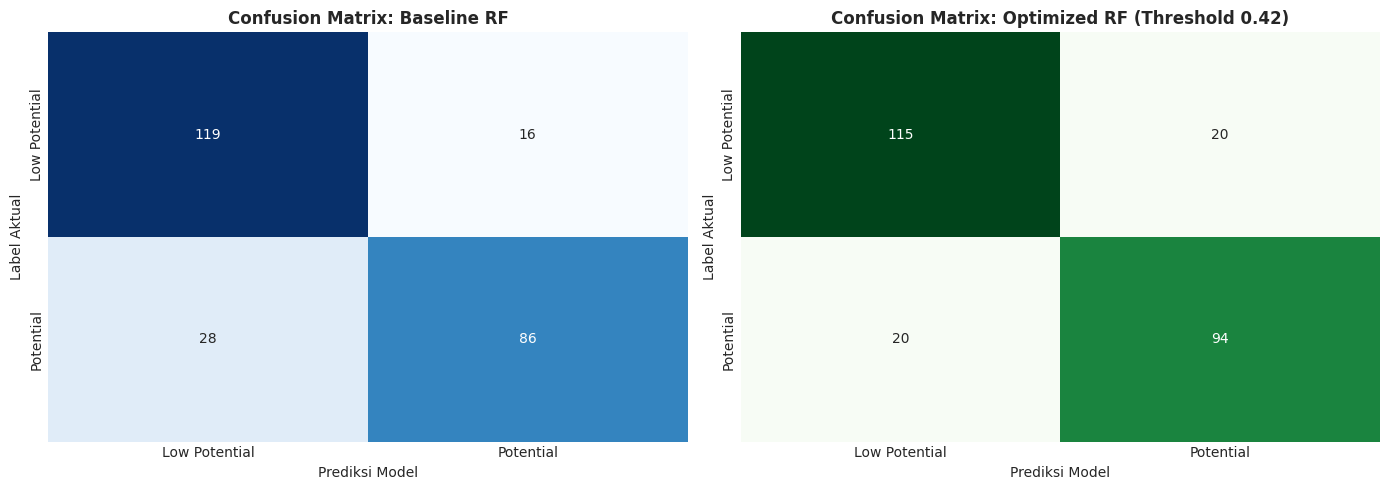

In [9]:
# Prediksi Final dengan Optimal Threshold
y_pred_optimized = (y_probs_oof >= optimal_threshold).astype(int)
y_pred_default_t = (y_probs_oof >= 0.50).astype(int)

eval_comparison = pd.DataFrame([
    {
        'Model / Konfigurasi': '1. Baseline Random Forest (Default)',
        'Akurasi (%)': round(baseline_results['Akurasi (%)'], 2),
        'Precision (%)': round(baseline_results['Precision (%)'], 2),
        'Recall (%)': round(baseline_results['Recall (%)'], 2),
        'F1-Score (%)': round(baseline_results['F1-Score (%)'], 2),
        'ROC-AUC (%)': round(baseline_results['ROC-AUC (%)'], 2)
    },
    {
        'Model / Konfigurasi': '2. Tuned RF (GridSearch @ Threshold 0.50)',
        'Akurasi (%)': round(accuracy_score(y, y_pred_default_t) * 100, 2),
        'Precision (%)': round(precision_score(y, y_pred_default_t) * 100, 2),
        'Recall (%)': round(recall_score(y, y_pred_default_t) * 100, 2),
        'F1-Score (%)': round(f1_score(y, y_pred_default_t) * 100, 2),
        'ROC-AUC (%)': round(roc_auc_score(y, y_probs_oof) * 100, 2)
    },
    {
        'Model / Konfigurasi': f'3. Tuned RF (GridSearch @ Optimal Threshold {optimal_threshold:.2f})',
        'Akurasi (%)': round(accuracy_score(y, y_pred_optimized) * 100, 2),
        'Precision (%)': round(precision_score(y, y_pred_optimized) * 100, 2),
        'Recall (%)': round(recall_score(y, y_pred_optimized) * 100, 2),
        'F1-Score (%)': round(f1_score(y, y_pred_optimized) * 100, 2),
        'ROC-AUC (%)': round(roc_auc_score(y, y_probs_oof) * 100, 2)
    }
])

print("=== TABEL PERBANDINGAN PENINGKATAN PERFORMA MODEL ===")
display(eval_comparison)

# Visualisasi Confusion Matrix Komparatif
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_base = confusion_matrix(y, (cross_val_predict(rf_baseline, X_scaled, y, cv=cv_stratified) >= 0.5).astype(int))
cm_opt = confusion_matrix(y, y_pred_optimized)

sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Low Potential', 'Potential'], yticklabels=['Low Potential', 'Potential'], cbar=False)
axes[0].set_title('Confusion Matrix: Baseline RF', fontweight='bold')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Label Aktual')

sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Low Potential', 'Potential'], yticklabels=['Low Potential', 'Potential'], cbar=False)
axes[1].set_title(f'Confusion Matrix: Optimized RF (Threshold {optimal_threshold:.2f})', fontweight='bold')
axes[1].set_xlabel('Prediksi Model')
axes[1].set_ylabel('Label Aktual')

plt.tight_layout()
plt.show()


---
## 10. Analisis Permutation Feature Importance
Berbeda dari *Gini Importance* yang dapat bias terhadap fitur berkardinalitas tinggi, **Permutation Importance** mengukur penurunan performa saat nilai fitur diacak (*shuffled*), memberikan gambaran objektif mengenai fitur yang benar-benar esensial.


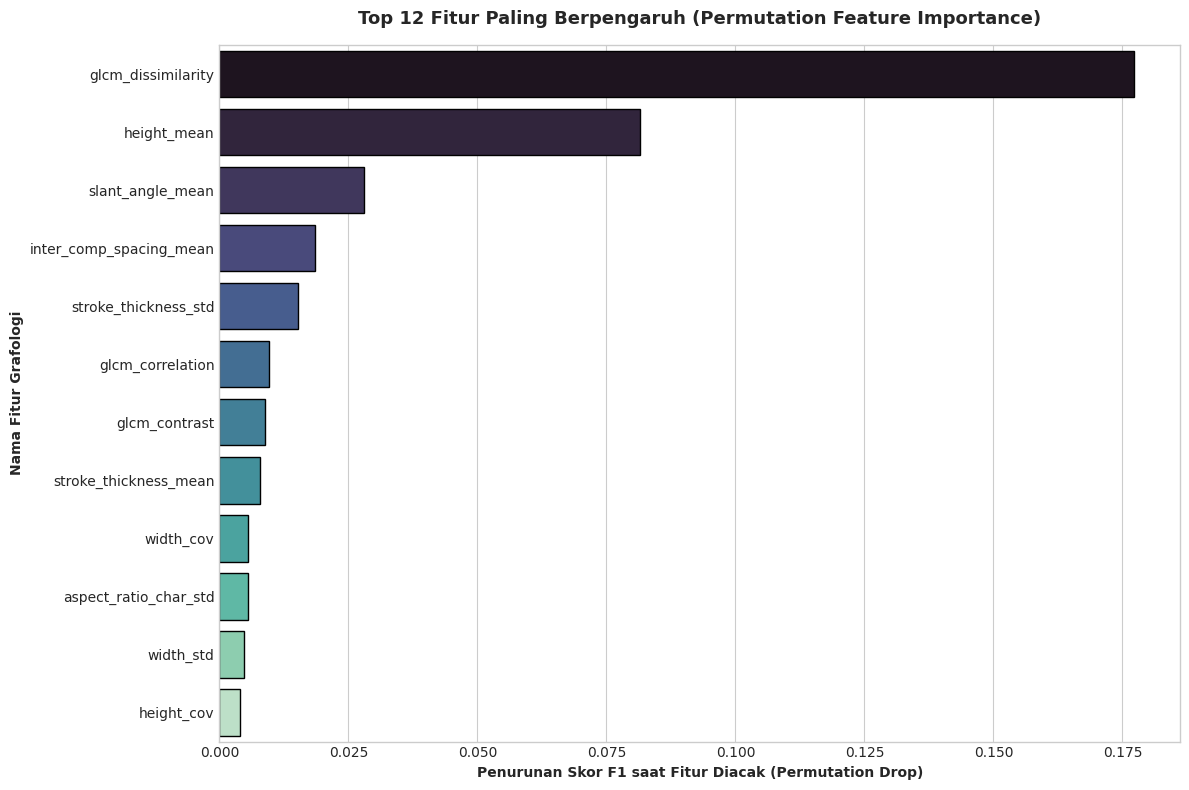

Tabel Top 12 Permutation Feature Importance:


,Fitur,Importance Mean,Importance Std
0,glcm_dissimilarity,0.177288,0.021821
1,height_mean,0.081599,0.016390
2,slant_angle_mean,0.028044,0.007755
3,inter_comp_spacing_mean,0.018472,0.003047
4,stroke_thickness_std,0.015150,0.003413
5,glcm_correlation,0.009531,0.002569
6,glcm_contrast,0.008879,0.005410
7,stroke_thickness_mean,0.007796,0.003356
8,width_cov,0.005592,0.002273
9,aspect_ratio_char_std,0.005545,0.002246


In [10]:
# Fit model terbaik pada seluruh data untuk analisis
best_rf_model.fit(X_scaled, y)

perm_importance = permutation_importance(best_rf_model, X_scaled, y, n_repeats=30, random_state=RANDOM_STATE, scoring='f1', n_jobs=-1)

sorted_idx = perm_importance.importances_mean.argsort()[::-1]

perm_df = pd.DataFrame({
    'Fitur': [feature_cols[i] for i in sorted_idx],
    'Importance Mean': perm_importance.importances_mean[sorted_idx],
    'Importance Std': perm_importance.importances_std[sorted_idx]
})

plt.figure(figsize=(12, 8))
sns.barplot(
    x='Importance Mean', y='Fitur', data=perm_df.head(12),
    hue='Fitur', palette='mako', edgecolor='black', legend=False
)
plt.title("Top 12 Fitur Paling Berpengaruh (Permutation Feature Importance)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Penurunan Skor F1 saat Fitur Diacak (Permutation Drop)", fontweight='bold')
plt.ylabel("Nama Fitur Grafologi", fontweight='bold')
plt.tight_layout()
plt.show()

print("Tabel Top 12 Permutation Feature Importance:")
display(perm_df.head(12))


---
## 11. Menyimpan Model Final Teroptimasi (`.pkl`)
Menyimpan model Random Forest yang telah dioptimalkan beserta metadata ambang batas (*optimal threshold*) dan standarisasi fitur.


In [11]:
# Definisikan model_name dan file target
model_name = "Optimized Random Forest Classifier"
OPTIMIZED_MODEL_FILE = "best_optimized_random_forest.pkl"
OPTIMIZED_META_FILE = "rf_optimization_metadata.json"

# Pastikan model di-fit pada seluruh data
if 'best_rf_model' in locals():
    final_model = best_rf_model
elif 'random_search' in locals() and hasattr(random_search, 'best_estimator_'):
    final_model = random_search.best_estimator_
elif 'rf_baseline' in locals():
    final_model = rf_baseline
else:
    final_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)

final_model.fit(X_scaled, y)
joblib.dump(final_model, OPTIMIZED_MODEL_FILE)

# Ambil parameter terbaik yang tersedia
best_params_dict = {}
if 'grid_search' in locals() and hasattr(grid_search, 'best_params_'):
    best_params_dict = {k: (v if not isinstance(v, (np.generic, np.ndarray)) else v.item()) for k, v in grid_search.best_params_.items()}
elif 'random_search' in locals() and hasattr(random_search, 'best_params_'):
    best_params_dict = {k: (v if not isinstance(v, (np.generic, np.ndarray)) else v.item()) for k, v in random_search.best_params_.items()}

# Simpan metadata tuning lengkap
optimization_meta = {
    'model_name': model_name,
    'best_params': best_params_dict,
    'optimal_decision_threshold': float(round(optimal_threshold, 4)) if 'optimal_threshold' in locals() else 0.50,
    'feature_names': feature_cols
}

with open(OPTIMIZED_META_FILE, 'w', encoding='utf-8') as f:
    json.dump(optimization_meta, f, indent=2)

print(f"[SUCCESS] Model '{model_name}' berhasil disimpan di : '{OPTIMIZED_MODEL_FILE}'")
print(f"[SUCCESS] Metadata Optimasi disimpan di            : '{OPTIMIZED_META_FILE}'")
print("\nSelesai! Model teroptimasi siap digunakan pada alur inferensi dan aplikasi app.py.")


✅ Model Teroptimasi berhasil disimpan di : 'best_optimized_random_forest.pkl'
✅ Metadata Optimasi disimpan di         : 'rf_optimization_metadata.json'

Selesai! Model siap digunakan pada alur inferensi dan aplikasi.
